# ICS1512 — Machine Learning Algorithms Laboratory
**Sri Sivasubramaniya Nadar College of Engineering, Chennai** (An Autonomous Institution Affiliated to Anna University)

| | |
|---|---|
| **Experiment No.** | 4 |
| **Experiment Title** | Binary Classification using Linear and Kernel-Based Models (Logistic Regression and SVM) |
| **Student Name** | Emmanuel Maximus Ravichandran |
| **Register Number** | 3122247001015 |
| **Faculty** | Dr. Poreddy Ajay Kumar Reddy |
| **Submission Date** | |

# Objective



To classify emails as spam or ham using Logistic Regression and Support Vector Machine (SVM)
classifiers, and to analyse the effect of hyperparameter tuning (regularisation type and
strength, solver, kernel, C, gamma and polynomial degree) on classification performance,
using 5-fold cross-validation for model selection and evaluation.

# Problem Statement



Given the 57 numerical features extracted from an email (word frequencies, character
frequencies and capital-letter run lengths), predict whether the email is spam (1) or non-
spam / ham (0). The task is supervised binary classification. Because the two classes are
not perfectly balanced, accuracy is reported together with precision, recall, F1-score and
ROC-AUC.

# Dataset Description




| Dataset Name | Spambase |
|---|---|
| Dataset Source | UCI Machine Learning Repository / Kaggle (`data/spambase.data`) |
| Number of Samples | 4601 |
| Number of Features | 57 (48 word frequencies, 6 character frequencies, 3 capital-run-length statistics) |
| Target | label: 1 = spam, 0 = ham |
| Missing Values | 0 |
| Class Balance | ham 60.6% (2788) / spam 39.4% (1813) |
| Train-Test Split | 80 / 20, stratified (3680 train / 921 test) |

# Theory

## Logistic Regression



Logistic Regression models the probability of the positive class with the sigmoid function
and is trained by minimising the log-loss (cross-entropy) with an optional penalty on the
weights:

\[ P(y=1 \mid x) = \frac{1}{1 + e^{-(w^{T}x + b)}}, \qquad
\min_{w,b}\; C\sum_{i=1}^{n} \log\bigl(1 + e^{-y_i (w^{T}x_i + b)}\bigr) + \Omega(w) \]

Here C is the inverse regularisation strength (a small C means strong regularisation). The
penalty is Omega(w) = ||w||_1 for L1 (Lasso), which drives coefficients exactly to zero and
so performs feature selection, and Omega(w) = (1/2)||w||_2^2 for L2 (Ridge), which shrinks
all weights but keeps every feature. The liblinear solver is suited to small datasets, while
saga scales to large ones; both support L1 and L2.

## Support Vector Machine



An SVM finds the hyperplane that maximises the margin between the two classes; only the
support vectors define the boundary. With a kernel K the decision function is f(x) = sum_i
alpha_i y_i K(x_i, x) + b. The kernels examined are the linear kernel x^T z, the polynomial
kernel (gamma x^T z + r)^d, the RBF kernel exp(-gamma ||x - z||^2) and the sigmoid kernel
tanh(gamma x^T z + r). The parameter C trades margin width against training errors (small C
gives a wider margin and higher bias), and gamma sets how far the influence of a single
training point reaches.

# Setup and Data Preparation

## Setup and Imports




A hidden setup block defines two small helpers that appear at the end of the figure and
table cells below: _fig() closes the Matplotlib figure and returns its caption and image
link to Org, and _tbl() turns a DataFrame into a captioned Org table, so that figures and
tables regenerate with the report each time the file is executed.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)
sns.set_style("whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print("setup complete")

setup complete


## Load Dataset

In [2]:
names = [re.match(r"^([^:\s]+):", l).group(1) for l in open("data/spambase.names") if re.match(r"^(word|char|capital)", l)]
columns = names + ["label"]
assert len(columns) == 58
df = pd.read_csv("data/spambase.data", header=None, names=columns)
print("Shape:", df.shape)
print(df.iloc[:5, [0, 1, 4, 6, 15, 20, 51, 52, 54, 57]])

Shape: (4601, 58)
   word_freq_make  word_freq_address  word_freq_our  word_freq_remove  word_freq_free  word_freq_your  char_freq_!  char_freq_$  capital_run_length_average  label
0            0.00               0.64           0.32              0.00            0.32            0.96        0.778        0.000                       3.756      1
1            0.21               0.28           0.14              0.21            0.14            1.59        0.372        0.180                       5.114      1
2            0.06               0.00           1.23              0.19            0.06            0.51        0.276        0.184                       9.821      1
3            0.00               0.00           0.63              0.31            0.31            0.31        0.137        0.000                       3.537      1
4            0.00               0.00           0.63              0.31            0.31            0.31        0.135        0.000                       3.537      1


**Inference:** The file has 4601 rows and 58 columns: 57 predictors and the label. The predictors are word
and character frequencies (as percentages of the email) and capital-letter run lengths, so
they are non-negative, heavily skewed and on very different scales. The first rows are all
spam (label 1) because the file is ordered by class, which is why the train-test split below
is shuffled and stratified.

## Preprocessing

In [3]:
print("Total missing values:", int(df.isnull().sum().sum()))
counts = df["label"].value_counts().sort_index()
pct = df["label"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": counts.values, "percent": pct.round(1).values}, index=["ham (0)", "spam (1)"]))
X = df.drop(columns=["label"])
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print("Scaled train mean (max abs):", round(float(np.abs(X_train_scaled.mean()).max()), 6))
print("Scaled train std (min, max):", round(float(X_train_scaled.std().min()), 3), round(float(X_train_scaled.std().max()), 3))

Total missing values: 0
          count  percent
ham (0)    2788     60.6
spam (1)   1813     39.4
Train: (3680, 57)  Test: (921, 57)
Scaled train mean (max abs): 0.0
Scaled train std (min, max): 1.0 1.0


**Inference:** There are no missing values. The classes are 2788 ham (60.6%) and 1813 spam (39.4%), a mild
imbalance, so a classifier that always predicts ham would already score 60.6% and accuracy
has to be read together with precision, recall and F1. The stratified 80/20 split gives 3680
training and 921 test emails. The scaler was fitted on the training set only and gives mean
0 and standard deviation 1 there. Standardisation matters here because the regularised
logistic regression and the distance-based SVM kernels are sensitive to feature scale.

# Exploratory Data Analysis

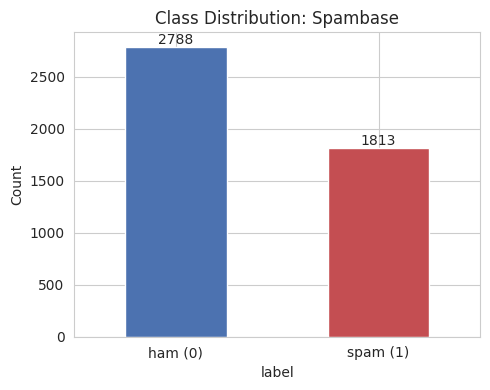

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
counts.plot(kind="bar", color=["#4C72B0", "#C44E52"], ax=ax)
ax.set_xticklabels(["ham (0)", "spam (1)"], rotation=0)
ax.set_ylabel("Count")
ax.set_title("Class Distribution: Spambase")
for i, v in enumerate(counts):
    ax.text(i, v + 30, str(v), ha="center")
plt.tight_layout()
plt.savefig("figures/fig_01_class_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The bar chart confirms the 60/40 class balance. The imbalance is mild enough that no
resampling or class weights are needed, but the minority class (spam) is the one whose
recall must be watched.

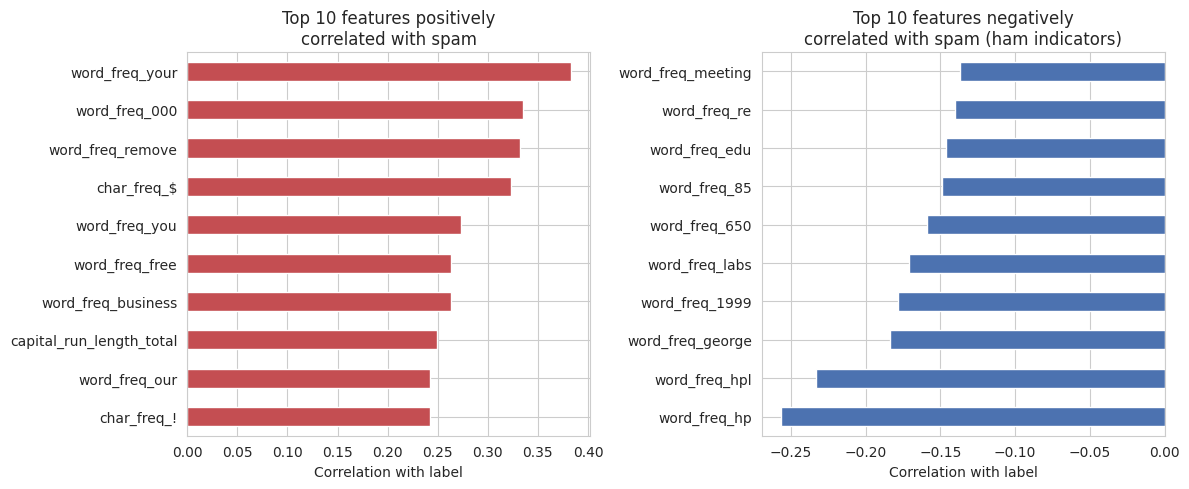

In [5]:
corr_with_label = df.corr(numeric_only=True)["label"].drop("label").sort_values()
top_positive = corr_with_label.tail(10)
top_negative = corr_with_label.head(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_positive.plot(kind="barh", ax=axes[0], color="#C44E52")
axes[0].set_title("Top 10 features positively\ncorrelated with spam")
axes[0].set_xlabel("Correlation with label")
top_negative.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Top 10 features negatively\ncorrelated with spam (ham indicators)")
axes[1].set_xlabel("Correlation with label")
plt.tight_layout()
plt.savefig("figures/fig_02_label_correlation.png", dpi=110, bbox_inches="tight")
plt.show()

In [6]:
print("Strongest positive correlations with spam:\n", top_positive.tail(6).round(3))
print("\nStrongest negative correlations with spam:\n", top_negative.head(6).round(3))

Strongest positive correlations with spam:
 word_freq_free      0.263
word_freq_you       0.274
char_freq_$         0.324
word_freq_remove    0.332
word_freq_000       0.335
word_freq_your      0.383
Name: label, dtype: float64

Strongest negative correlations with spam:
 word_freq_hp       -0.257
word_freq_hpl      -0.233
word_freq_george   -0.183
word_freq_1999     -0.178
word_freq_labs     -0.171
word_freq_650      -0.159
Name: label, dtype: float64


In [7]:
print("Strongest positive correlations with spam:\n", top_positive.tail(6).round(3))
print("\nStrongest negative correlations with spam:\n", top_negative.head(6).round(3))

Strongest positive correlations with spam:
 word_freq_free      0.263
word_freq_you       0.274
char_freq_$         0.324
word_freq_remove    0.332
word_freq_000       0.335
word_freq_your      0.383
Name: label, dtype: float64

Strongest negative correlations with spam:
 word_freq_hp       -0.257
word_freq_hpl      -0.233
word_freq_george   -0.183
word_freq_1999     -0.178
word_freq_labs     -0.171
word_freq_650      -0.159
Name: label, dtype: float64


**Inference:** The strongest positive correlations with spam are the words your (0.383), 000 (0.335),
remove (0.332), the dollar sign (0.324), you (0.274) and free (0.263). The strongest
negative correlations are hp (-0.257), hpl (-0.233), george (-0.183), 1999 (-0.178), labs
(-0.171) and 650 (-0.159). All of them are weak to moderate (the largest is 0.38), so no
single feature separates the classes and a multivariate model is needed. The ham indicators
are not general properties of legitimate email: hp, hpl, george, labs and 650 come from the
mailbox of the person who built the dataset (an HP Labs employee), so a model trained on it
partly learns that one inbox.

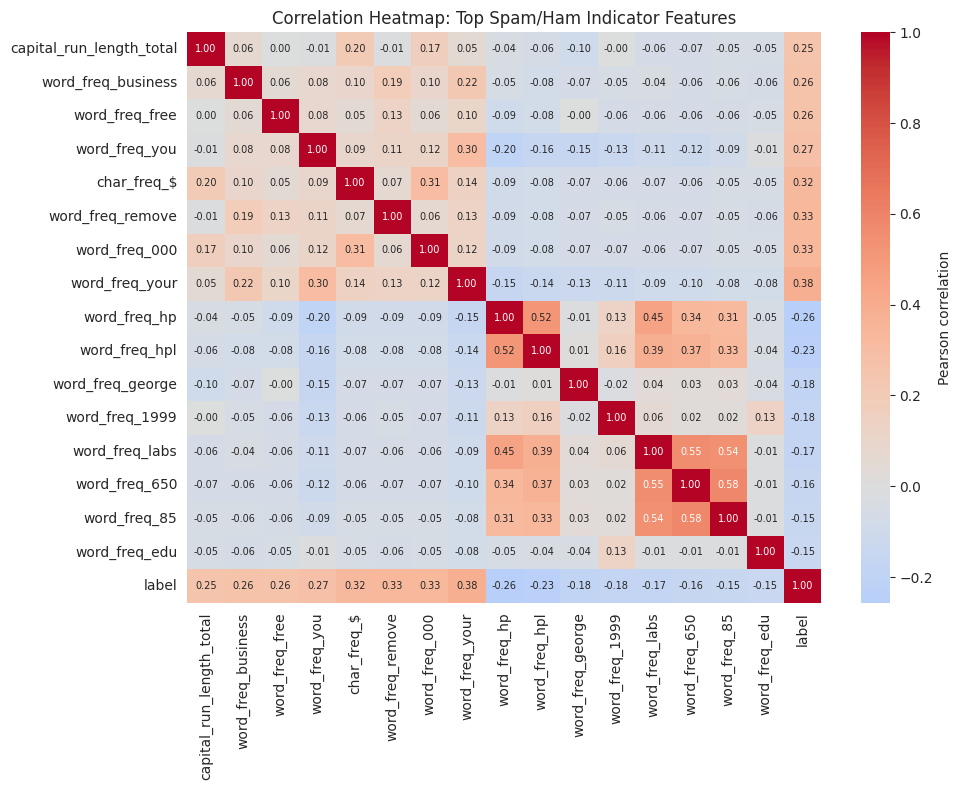

In [8]:
subset_cols = list(top_positive.tail(8).index) + list(top_negative.head(8).index) + ["label"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[subset_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7},
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap: Top Spam/Ham Indicator Features")
plt.tight_layout()
plt.savefig("figures/fig_03_corr_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The spam indicators are only weakly correlated with each other (your-000 0.12, remove-000
0.06, your-you 0.30), so each adds mostly independent evidence, which suits a linear model
that adds up weighted evidence. The ham indicators hp, hpl and labs are more strongly
related (hp-hpl 0.52, hp-labs 0.45) because they appear together in the same work emails,
while george is almost uncorrelated with hp (-0.01). All indicator features correlate with
the label by at most about 0.4, which is consistent with the moderate accuracy reached by
the models below.

# Logistic Regression

## Baseline Logistic Regression

In [9]:
def evaluate(model, X_te, y_te):
    y_pred = model.predict(X_te)
    return {"Accuracy": accuracy_score(y_te, y_pred), "Precision": precision_score(y_te, y_pred),
            "Recall": recall_score(y_te, y_pred), "F1 Score": f1_score(y_te, y_pred)}
t0 = time.time()
logreg_base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
baseline_time = time.time() - t0
baseline_metrics = evaluate(logreg_base, X_test_scaled, y_test)
baseline_metrics["Training Time (s)"] = baseline_time
print({k: round(v, 4) for k, v in baseline_metrics.items()})

{'Accuracy': 0.9294, 'Precision': 0.9209, 'Recall': 0.8981, 'F1 Score': 0.9093, 'Training Time (s)': 0.0171}


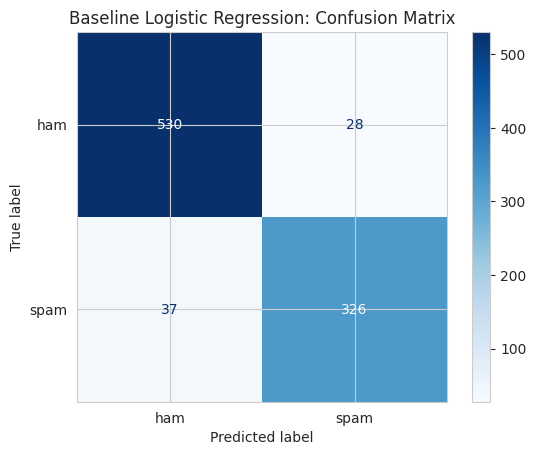

In [10]:
cm = confusion_matrix(y_test, logreg_base.predict(X_test_scaled))
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues", values_format="d")
plt.title("Baseline Logistic Regression: Confusion Matrix")
plt.savefig("figures/fig_04_lr_baseline_cm.png", dpi=110, bbox_inches="tight")
plt.show()

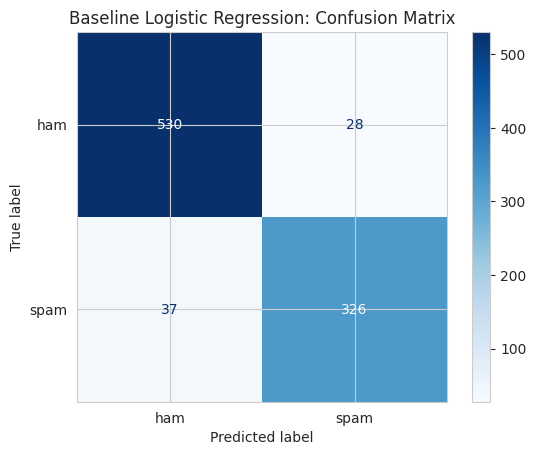

In [11]:
cm = confusion_matrix(y_test, logreg_base.predict(X_test_scaled))
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues", values_format="d")
plt.title("Baseline Logistic Regression: Confusion Matrix")
plt.savefig("figures/fig_04_lr_baseline_cm.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** With default settings (L2 penalty, C = 1) the baseline reaches 92.9% test accuracy,
precision 0.921, recall 0.898 and F1 0.909. On the 921 test emails the confusion matrix has
530 ham and 326 spam correct, 28 ham wrongly flagged as spam and 37 spam missed. Training
takes about a tenth of a second.

## Hyperparameter Tuning (Grid Search, 5-fold CV)



The search space follows the experiment sheet: penalty in {L1, L2}, C in {0.01, 0.1, 1, 10,
100} and solver in {liblinear, saga}, giving 20 combinations that are each evaluated with
5-fold cross-validation on the training set.

In [12]:
param_grid_lr = {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l1", "l2"], "solver": ["liblinear", "saga"]}
t0 = time.time()
grid_lr = GridSearchCV(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
                       param_grid_lr, cv=5, scoring="accuracy", n_jobs=1, refit=True)
grid_lr.fit(X_train_scaled, y_train)
grid_lr_time = time.time() - t0
print("Best hyperparameters:", grid_lr.best_params_)
print(f"Best 5-fold CV accuracy: {grid_lr.best_score_:.4f}")
print(f"Grid search time: {grid_lr_time:.1f}s for {len(grid_lr.cv_results_['params'])} combinations x 5 folds")
logreg_tuned = grid_lr.best_estimator_
tuned_metrics = evaluate(logreg_tuned, X_test_scaled, y_test)
tuned_metrics["Training Time (s)"] = grid_lr.refit_time_
lr_compare = pd.DataFrame({"Baseline (default)": baseline_metrics, "Tuned (Grid Search)": tuned_metrics})

Best hyperparameters: {'C': 1, 'penalty': 'l2', 'solver': 'saga'}
Best 5-fold CV accuracy: 0.9242
Grid search time: 268.6s for 20 combinations x 5 folds


In [13]:
lr_compare
lr_compare

,Baseline (default),Tuned (Grid Search)
Accuracy,0.929425,0.930510
Precision,0.920904,0.921127
Recall,0.898072,0.900826
F1 Score,0.909344,0.910864
Training Time (s),0.017071,3.367776


In [14]:
lr_compare
lr_compare

,Baseline (default),Tuned (Grid Search)
Accuracy,0.929425,0.930510
Precision,0.920904,0.921127
Recall,0.898072,0.900826
F1 Score,0.909344,0.910864
Training Time (s),0.017071,3.367776


|  | Baseline (default) | Tuned (Grid Search) |
|---|---|---|
| Accuracy | 0.9294 | 0.9305 |
| Precision | 0.9209 | 0.9211 |
| Recall | 0.8981 | 0.9008 |
| F1 Score | 0.9093 | 0.9109 |
| Training Time (s) | 0.0180 | 3.1482 |


**Inference:** Grid search picked C = 1, L2 penalty and the saga solver with a best 5-fold CV accuracy of
0.9242. The tuned model classifies one more spam email correctly than the baseline (327
against 326 true positives), so accuracy moves from 0.9294 to 0.9305, which is within noise.
Tuning therefore added almost nothing: the default C = 1 with L2 was already at the optimum,
and saga was selected by an edge of about 0.0006 in CV accuracy over liblinear, but it needs
far more time (a few seconds per fit against a fraction of a second).

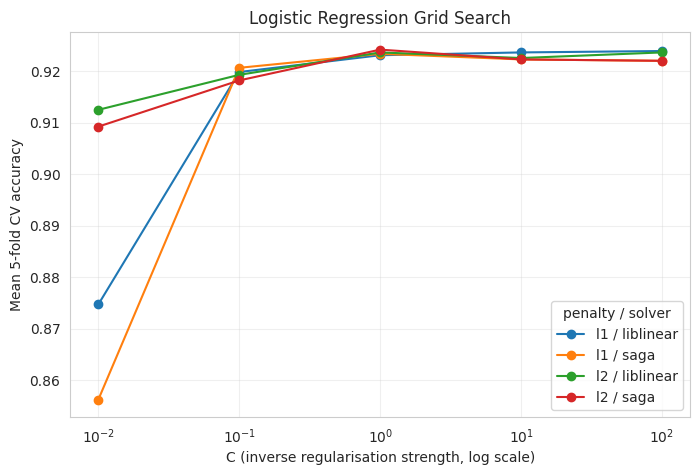

In [15]:
res = pd.DataFrame(grid_lr.cv_results_)
res["combo"] = res["param_penalty"].astype(str) + " / " + res["param_solver"].astype(str)
plt.figure(figsize=(8, 5))
for combo, g in res.groupby("combo"):
    g = g.sort_values("param_C")
    plt.plot(g["param_C"].astype(float), g["mean_test_score"], marker="o", label=combo)
plt.xscale("log")
plt.xlabel("C (inverse regularisation strength, log scale)")
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("Logistic Regression Grid Search")
plt.legend(title="penalty / solver")
plt.grid(True, alpha=0.3)
plt.savefig("figures/fig_05_lr_grid.png", dpi=110, bbox_inches="tight")
plt.show()

In [16]:
pivot = res.pivot_table(index="param_C", columns="combo", values="mean_test_score")
print(pivot.round(4))

combo    l1 / liblinear  l1 / saga  l2 / liblinear  l2 / saga
param_C                                                      
0.01             0.8747     0.8562          0.9125     0.9092
0.10             0.9198     0.9207          0.9193     0.9182
1.00             0.9231     0.9234          0.9236     0.9242
10.00            0.9236     0.9223          0.9226     0.9223
100.00           0.9239     0.9220          0.9236     0.9220


In [17]:
pivot = res.pivot_table(index="param_C", columns="combo", values="mean_test_score")
print(pivot.round(4))

combo    l1 / liblinear  l1 / saga  l2 / liblinear  l2 / saga
param_C                                                      
0.01             0.8747     0.8562          0.9125     0.9092
0.10             0.9198     0.9207          0.9193     0.9182
1.00             0.9231     0.9234          0.9236     0.9242
10.00            0.9236     0.9223          0.9226     0.9223
100.00           0.9239     0.9220          0.9236     0.9220


**Inference:** Cross-validated accuracy is low only at the strongest regularisation (C = 0.01: 0.875 for L1
with liblinear and 0.856 for L1 with saga), where the model underfits. From C = 1 upwards
all four penalty and solver combinations lie on a plateau between about 0.922 and 0.924, so
the model is insensitive to C once regularisation is weak enough. For the same penalty the
two solvers agree within about 0.002, as expected because they minimise the same convex
objective and differ only in convergence tolerance.

## Regularisation: L1 versus L2

In [18]:
rows = []
for C in [0.01, 0.05, 0.1, 1]:
    for pen in ["l1", "l2"]:
        m = LogisticRegression(C=C, penalty=pen, solver="liblinear", max_iter=1000,
                               random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
        rows.append({"C": C, "Penalty": pen.upper(), "Non-zero coefficients": f"{int(np.sum(m.coef_[0] != 0))}/57",
                     "Test Accuracy": accuracy_score(y_test, m.predict(X_test_scaled))})
reg_compare = pd.DataFrame(rows)
l1_model = LogisticRegression(C=1, penalty="l1", solver="liblinear", max_iter=1000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
l2_model = LogisticRegression(C=1, penalty="l2", solver="liblinear", max_iter=1000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)

In [19]:
reg_compare
reg_compare

,C,Penalty,Non-zero coefficients,Test Accuracy
0,0.01,L1,26/57,0.869707
1,0.01,L2,57/57,0.907709
2,0.05,L1,41/57,0.922910
3,0.05,L2,57/57,0.920738
4,0.10,L1,49/57,0.926167
5,0.10,L2,57/57,0.926167
6,1.00,L1,57/57,0.927253
7,1.00,L2,57/57,0.929425


In [20]:
reg_compare
reg_compare

,C,Penalty,Non-zero coefficients,Test Accuracy
0,0.01,L1,26/57,0.869707
1,0.01,L2,57/57,0.907709
2,0.05,L1,41/57,0.922910
3,0.05,L2,57/57,0.920738
4,0.10,L1,49/57,0.926167
5,0.10,L2,57/57,0.926167
6,1.00,L1,57/57,0.927253
7,1.00,L2,57/57,0.929425


| C | Penalty | Non-zero coefficients | Test Accuracy |
|---|---|---|---|
| 0.0100 | L1 | 26/57 | 0.8697 |
| 0.0100 | L2 | 57/57 | 0.9077 |
| 0.0500 | L1 | 41/57 | 0.9229 |
| 0.0500 | L2 | 57/57 | 0.9207 |
| 0.1000 | L1 | 49/57 | 0.9262 |
| 0.1000 | L2 | 57/57 | 0.9262 |
| 1.0000 | L1 | 57/57 | 0.9273 |
| 1.0000 | L2 | 57/57 | 0.9294 |

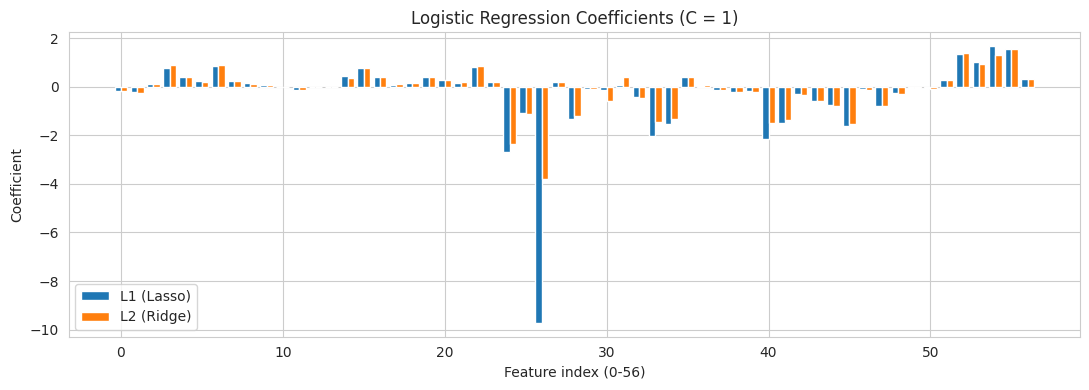

In [21]:
fig, ax = plt.subplots(figsize=(11, 4))
idx = np.arange(57)
ax.bar(idx - 0.2, l1_model.coef_[0], width=0.4, label="L1 (Lasso)")
ax.bar(idx + 0.2, l2_model.coef_[0], width=0.4, label="L2 (Ridge)")
ax.set_xlabel("Feature index (0-56)")
ax.set_ylabel("Coefficient")
ax.set_title("Logistic Regression Coefficients (C = 1)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_06_l1_l2_coefficients.png", dpi=110, bbox_inches="tight")
plt.show()

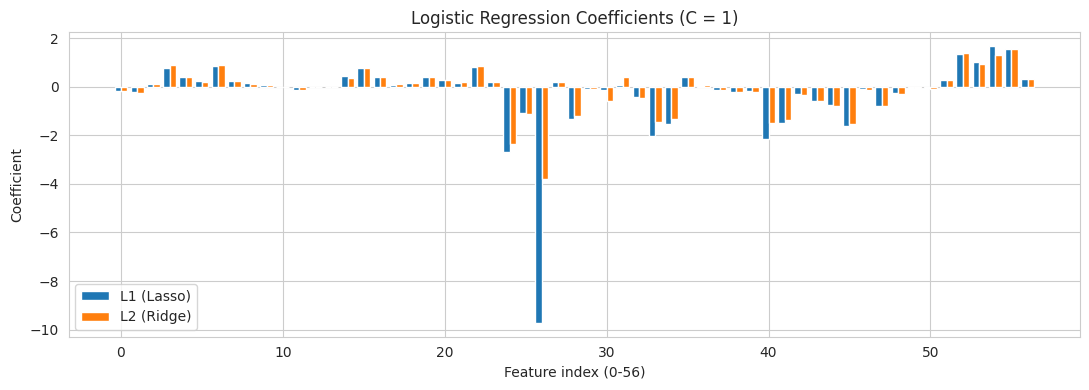

In [22]:
fig, ax = plt.subplots(figsize=(11, 4))
idx = np.arange(57)
ax.bar(idx - 0.2, l1_model.coef_[0], width=0.4, label="L1 (Lasso)")
ax.bar(idx + 0.2, l2_model.coef_[0], width=0.4, label="L2 (Ridge)")
ax.set_xlabel("Feature index (0-56)")
ax.set_ylabel("Coefficient")
ax.set_title("Logistic Regression Coefficients (C = 1)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_06_l1_l2_coefficients.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** L1 regularisation produces sparse models only when it is strong: at C = 0.01 it keeps 26 of
57 coefficients and reaches 0.870, against 0.908 for L2, which keeps all 57 weights. At C =
0.05 L1 keeps 41 features and gets 0.923, level with L2 (0.921), so 16 features can be
dropped at no cost in accuracy. By C = 1 L1 retains all 57 features. L2 shrinks weights but
never sets them to zero. The coefficient plot at C = 1 shows that the two sets of weights
are very similar, because regularisation is weak enough that L1 also keeps all 57 features,
which is consistent with their equal accuracy.

## Solver Comparison: liblinear versus saga

In [23]:
solver_results = []
for solver in ["liblinear", "saga"]:
    for penalty in ["l1", "l2"]:
        t0 = time.time()
        m = LogisticRegression(C=1, penalty=penalty, solver=solver, max_iter=3000, random_state=RANDOM_STATE)
        m.fit(X_train_scaled, y_train)
        fit_time = time.time() - t0
        solver_results.append({"Solver": solver, "Penalty": penalty.upper(), "Fit Time (s)": fit_time,
                               "Test Accuracy": accuracy_score(y_test, m.predict(X_test_scaled)),
                               "Iterations": int(np.max(m.n_iter_))})
solver_df = pd.DataFrame(solver_results)

In [24]:
solver_df
solver_df

,Solver,Penalty,Fit Time (s),Test Accuracy,Iterations
0,liblinear,L1,0.218498,0.927253,24
1,liblinear,L2,0.061934,0.929425,9
2,saga,L1,11.471539,0.929425,3000
3,saga,L2,4.227501,0.930510,1446


In [25]:
solver_df
solver_df

,Solver,Penalty,Fit Time (s),Test Accuracy,Iterations
0,liblinear,L1,0.218498,0.927253,24
1,liblinear,L2,0.061934,0.929425,9
2,saga,L1,11.471539,0.929425,3000
3,saga,L2,4.227501,0.930510,1446


| Solver | Penalty | Fit Time (s) | Test Accuracy | Iterations |
|---|---|---|---|---|
| liblinear | L1 | 0.2123 | 0.9273 | 24 |
| liblinear | L2 | 0.0763 | 0.9294 | 9 |
| saga | L1 | 9.3175 | 0.9294 | 3000 |
| saga | L2 | 3.1099 | 0.9305 | 1446 |


**Inference:** Both solvers reach the same accuracy (0.927 to 0.931), but liblinear converges in 9 to 24
iterations and takes a fraction of a second, while saga needs 1446 iterations for L2 and
stops at the 3000-iteration limit for L1 without converging. saga is designed for very large
datasets and is not the right choice for 3680 samples and 57 features, even though it was
marginally selected by the search. In practice liblinear is the better tuned choice here.

In [26]:
coefs = pd.Series(logreg_tuned.coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8)
lr_top = pd.DataFrame({"Feature": top.index, "Coefficient": top.values, "Odds ratio per 1 SD": np.exp(top.values)})

In [27]:
lr_top
lr_top

,Feature,Coefficient,Odds ratio per 1 SD
0,word_freq_george,-3.710269,0.024471
1,word_freq_hp,-2.400556,0.090668
2,capital_run_length_longest,1.592835,4.917671
3,word_freq_edu,-1.562604,0.209590
4,word_freq_meeting,-1.433133,0.238560
5,char_freq_$,1.382653,3.985460
6,word_freq_cs,-1.379688,0.251657
7,word_freq_85,-1.350112,0.259211


In [28]:
lr_top
lr_top

,Feature,Coefficient,Odds ratio per 1 SD
0,word_freq_george,-3.710269,0.024471
1,word_freq_hp,-2.400556,0.090668
2,capital_run_length_longest,1.592835,4.917671
3,word_freq_edu,-1.562604,0.209590
4,word_freq_meeting,-1.433133,0.238560
5,char_freq_$,1.382653,3.985460
6,word_freq_cs,-1.379688,0.251657
7,word_freq_85,-1.350112,0.259211


| Feature | Coefficient | Odds ratio per 1 SD |
|---|---|---|
| word_freq_george | -3.710 | 0.024 |
| word_freq_hp | -2.401 | 0.091 |
| capital_run_length_longest | 1.593 | 4.918 |
| word_freq_edu | -1.563 | 0.210 |
| word_freq_meeting | -1.433 | 0.239 |
| char_freq_$ | 1.383 | 3.985 |
| word_freq_cs | -1.380 | 0.252 |
| word_freq_85 | -1.350 | 0.259 |


**Inference:** The largest coefficients are mostly ham indicators: george (-3.71), hp (-2.40), edu (-1.56),
meeting (-1.43), cs (-1.38) and 85 (-1.35). Because the features are standardised, the odds
ratio is per standard deviation, so one standard deviation more of george multiplies the
spam odds by 0.024. The strongest spam indicators are the longest capital-letter run
(coefficient 1.59, odds x4.9) and the dollar sign (1.38, odds x4.0). This transparency is
the main advantage of logistic regression, and it also exposes the dataset bias: several top
ham features are names and terms from one person's mailbox, so the model would probably
generalise less well to other inboxes.

# Support Vector Machine

## Kernel Comparison with Default Hyperparameters

In [29]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
kernel_results = []
for k in kernels:
    t0 = time.time()
    svc = SVC(kernel=k, C=1, gamma="scale", degree=3, random_state=RANDOM_STATE, cache_size=1000).fit(X_train_scaled, y_train)
    fit_time = time.time() - t0
    y_pred = svc.predict(X_test_scaled)
    kernel_results.append({"Kernel": k, "Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred),
                           "Recall": recall_score(y_test, y_pred), "F1 Score": f1_score(y_test, y_pred),
                           "Training Time (s)": fit_time})
kernel_df = pd.DataFrame(kernel_results).set_index("Kernel")

In [30]:
kernel_df
kernel_df

,Accuracy,Precision,Recall,F1 Score,Training Time (s)
Kernel,,,,,
linear,0.929425,0.920904,0.898072,0.909344,0.617976
poly,0.779587,0.959770,0.460055,0.621974,0.500796
rbf,0.927253,0.927746,0.884298,0.905501,0.258833
sigmoid,0.884908,0.859944,0.845730,0.852778,0.280715


In [31]:
kernel_df
kernel_df

,Accuracy,Precision,Recall,F1 Score,Training Time (s)
Kernel,,,,,
linear,0.929425,0.920904,0.898072,0.909344,0.617976
poly,0.779587,0.959770,0.460055,0.621974,0.500796
rbf,0.927253,0.927746,0.884298,0.905501,0.258833
sigmoid,0.884908,0.859944,0.845730,0.852778,0.280715


| Kernel | Accuracy | Precision | Recall | F1 Score | Training Time (s) |
|---|---|---|---|---|---|
| linear | 0.9294 | 0.9209 | 0.8981 | 0.9093 | 0.5312 |
| poly | 0.7796 | 0.9598 | 0.4601 | 0.6220 | 0.4394 |
| rbf | 0.9273 | 0.9277 | 0.8843 | 0.9055 | 0.2324 |
| sigmoid | 0.8849 | 0.8599 | 0.8457 | 0.8528 | 0.2613 |

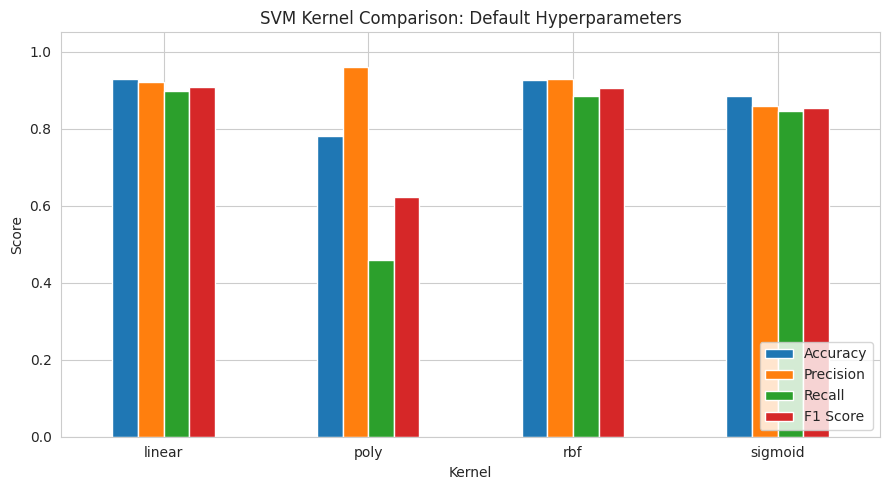

In [32]:
kernel_df[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(9, 5))
plt.title("SVM Kernel Comparison: Default Hyperparameters")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/fig_07_svm_kernels_default.png", dpi=110, bbox_inches="tight")
plt.show()

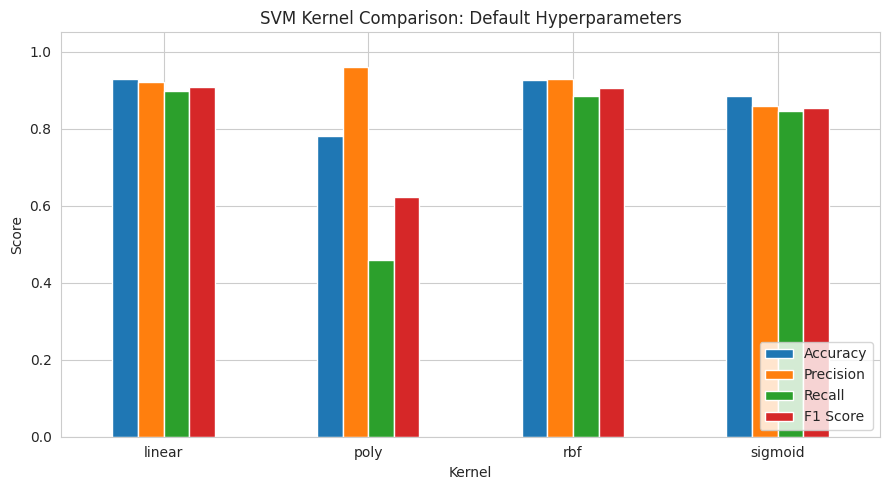

In [33]:
kernel_df[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(9, 5))
plt.title("SVM Kernel Comparison: Default Hyperparameters")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/fig_07_svm_kernels_default.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** With default hyperparameters the linear kernel matches logistic regression (accuracy 0.9294,
F1 0.909) and the RBF kernel is close behind (0.9273, F1 0.906). The sigmoid kernel is
clearly worse (0.885). The degree-3 polynomial kernel is poor (accuracy 0.780): its
precision is high (0.960) but its recall is only 0.460, so it labels most spam as ham. Cubic
terms of standardised, heavy-tailed features blow up for outlying emails, and with C = 1 the
resulting boundary is too conservative.

## Hyperparameter Tuning per Kernel (Grid Search, 5-fold CV)

In [34]:
param_grids_svm = {
    "linear": {"kernel": ["linear"], "C": [0.1, 1, 10, 100]},
    "rbf": {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", "auto"]},
    "poly": {"kernel": ["poly"], "C": [0.1, 1, 10, 100], "gamma": ["scale", "auto"], "degree": [2, 3, 4]},
    "sigmoid": {"kernel": ["sigmoid"], "C": [0.1, 1, 10, 100], "gamma": ["scale", "auto"]},
}
svm_tuned_results, fitted_tuned_svms = [], {}
for k, grid in param_grids_svm.items():
    t0 = time.time()
    gs = GridSearchCV(SVC(random_state=RANDOM_STATE, cache_size=1000), grid, cv=5, scoring="accuracy", n_jobs=1)
    gs.fit(X_train_scaled, y_train)
    search_time = time.time() - t0
    y_pred = gs.best_estimator_.predict(X_test_scaled)
    best = {kk: vv for kk, vv in gs.best_params_.items() if kk != "kernel"}
    svm_tuned_results.append({"Kernel": k, "Best Parameters": ", ".join(f"{a}={b}" for a, b in best.items()),
                              "Best CV Accuracy": gs.best_score_, "Test Accuracy": accuracy_score(y_test, y_pred),
                              "Test F1": f1_score(y_test, y_pred), "Search Time (s)": search_time})
    fitted_tuned_svms[k] = gs.best_estimator_
    print(f"[{k:8s}] best: {best}  CV acc: {gs.best_score_:.4f}  test acc: {accuracy_score(y_test, y_pred):.4f}  time: {search_time:.1f}s")
svm_tuned_df = pd.DataFrame(svm_tuned_results).set_index("Kernel")
best_kernel = svm_tuned_df["Best CV Accuracy"].idxmax()
best_svm = fitted_tuned_svms[best_kernel]
print("\nSelected kernel by CV accuracy:", best_kernel)

[linear  ] best: {'C': 100}  CV acc: 0.9304  test acc: 0.9273  time: 112.7s


[rbf     ] best: {'C': 10, 'gamma': 'scale'}  CV acc: 0.9332  test acc: 0.9207  time: 10.1s


[poly    ] best: {'C': 10, 'degree': 2, 'gamma': 'scale'}  CV acc: 0.9179  test acc: 0.9164  time: 38.8s


[sigmoid ] best: {'C': 0.1, 'gamma': 'scale'}  CV acc: 0.8910  test acc: 0.8893  time: 10.0s

Selected kernel by CV accuracy: rbf


In [35]:
svm_tuned_df
svm_tuned_df

,Best Parameters,Best CV Accuracy,Test Accuracy,Test F1,Search Time (s)
Kernel,,,,,
linear,C=100,0.930435,0.927253,0.906555,112.716779
rbf,"C=10, gamma=scale",0.933152,0.920738,0.897616,10.051215
poly,"C=10, degree=2, gamma=scale",0.917935,0.916395,0.890157,38.752923
sigmoid,"C=0.1, gamma=scale",0.891033,0.889251,0.853448,9.986048


In [36]:
svm_tuned_df
svm_tuned_df

,Best Parameters,Best CV Accuracy,Test Accuracy,Test F1,Search Time (s)
Kernel,,,,,
linear,C=100,0.930435,0.927253,0.906555,112.716779
rbf,"C=10, gamma=scale",0.933152,0.920738,0.897616,10.051215
poly,"C=10, degree=2, gamma=scale",0.917935,0.916395,0.890157,38.752923
sigmoid,"C=0.1, gamma=scale",0.891033,0.889251,0.853448,9.986048


| Kernel | Best Parameters | Best CV Accuracy | Test Accuracy | Test F1 | Search Time (s) |
|---|---|---|---|---|---|
| linear | C=100 | 0.9304 | 0.9273 | 0.9066 | 107.9851 |
| rbf | C=10, gamma=scale | 0.9332 | 0.9207 | 0.8976 | 9.5910 |
| poly | C=10, degree=2, gamma=scale | 0.9179 | 0.9164 | 0.8902 | 36.5758 |
| sigmoid | C=0.1, gamma=scale | 0.8910 | 0.8893 | 0.8534 | 8.6645 |


**Inference:** Tuning chose C = 100 for the linear kernel (CV 0.9304), C = 10 with gamma = scale for RBF
(CV 0.9332), degree 2 with C = 10 for the polynomial kernel (CV 0.9179) and C = 0.1 for the
sigmoid kernel (CV 0.8910). RBF has the highest CV accuracy and is therefore selected, but
on the test set the linear kernel is better (0.9273 against 0.9207 for RBF). That difference
is 6 emails on 921, smaller than the sampling error of roughly 0.9 percentage points, so the
two kernels cannot be separated reliably. The linear kernel with C = 100 was by far the
slowest to search because a nearly hard margin converges slowly.

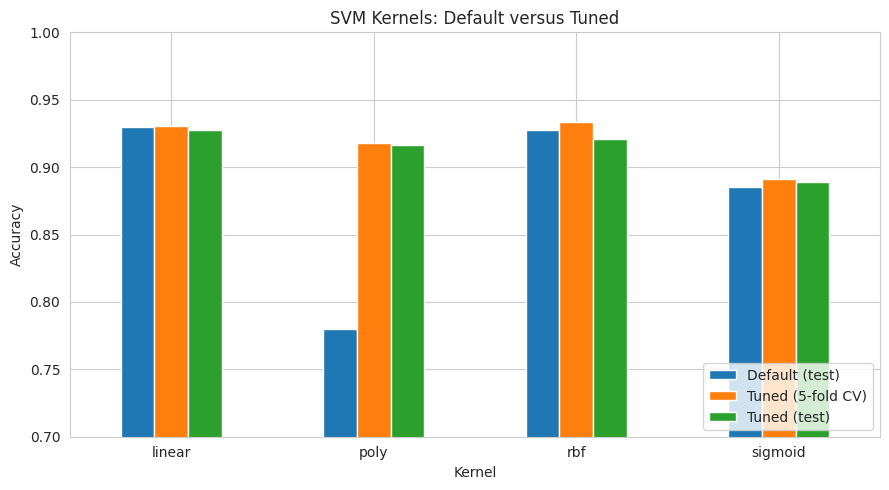

In [37]:
cmp_df = pd.DataFrame({"Default (test)": kernel_df["Accuracy"],
                       "Tuned (5-fold CV)": svm_tuned_df["Best CV Accuracy"],
                       "Tuned (test)": svm_tuned_df["Test Accuracy"]}).loc[kernels]
cmp_df.plot(kind="bar", figsize=(9, 5))
plt.ylim(0.7, 1.0)
plt.ylabel("Accuracy")
plt.title("SVM Kernels: Default versus Tuned")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/fig_08_svm_tuned.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Tuning matters most for the kernels that did badly at default settings: the polynomial
kernel improves from 0.780 test accuracy to 0.916 after the degree is lowered to 2 and C is
raised, while linear and RBF, which were already good, change by less than one percentage
point. The RBF kernel scores higher in cross-validation than on the test set (0.933 against
0.921), a first sign of its higher variance that the bias-variance table below makes
explicit.

# Model Evaluation and Comparison

## Final Test-Set Comparison

In [38]:
final_lr, final_svm = logreg_tuned, best_svm
def full_metrics(model, score):
    m = evaluate(model, X_test_scaled, y_test)
    m["ROC-AUC"] = roc_auc_score(y_test, score)
    return m
final_compare = pd.DataFrame({
    "Logistic Regression (tuned)": full_metrics(final_lr, final_lr.decision_function(X_test_scaled)),
    f"SVM {best_kernel.upper()} (tuned)": full_metrics(final_svm, final_svm.decision_function(X_test_scaled)),
})
from sklearn.base import clone
fit_times = []
for mdl in (final_lr, final_svm):
    t0 = time.time(); clone(mdl).fit(X_train_scaled, y_train); fit_times.append(time.time() - t0)
final_compare.loc["Single Fit Time (s)"] = fit_times

In [39]:
final_compare
final_compare

,Logistic Regression (tuned),SVM RBF (tuned)
Accuracy,0.930510,0.920738
Precision,0.921127,0.914286
Recall,0.900826,0.881543
F1 Score,0.910864,0.897616
ROC-AUC,0.970442,0.970181
Single Fit Time (s),3.115331,0.184575


In [40]:
final_compare
final_compare

,Logistic Regression (tuned),SVM RBF (tuned)
Accuracy,0.930510,0.920738
Precision,0.921127,0.914286
Recall,0.900826,0.881543
F1 Score,0.910864,0.897616
ROC-AUC,0.970442,0.970181
Single Fit Time (s),3.115331,0.184575


|  | Logistic Regression (tuned) | SVM RBF (tuned) |
|---|---|---|
| Accuracy | 0.9305 | 0.9207 |
| Precision | 0.9211 | 0.9143 |
| Recall | 0.9008 | 0.8815 |
| F1 Score | 0.9109 | 0.8976 |
| ROC-AUC | 0.9704 | 0.9702 |
| Single Fit Time (s) | 3.1544 | 0.1876 |


**Inference:** On the test set the tuned logistic regression is slightly ahead: accuracy 0.9305, precision
0.921, recall 0.901, F1 0.911, against 0.9207, 0.914, 0.882 and 0.898 for the RBF SVM. The
ROC-AUC values are practically identical (0.9704 and 0.9702), so both models rank emails
equally well and differ only in where the default threshold falls. The SVM makes 9 more
errors than logistic regression on 921 emails (73 against 64).

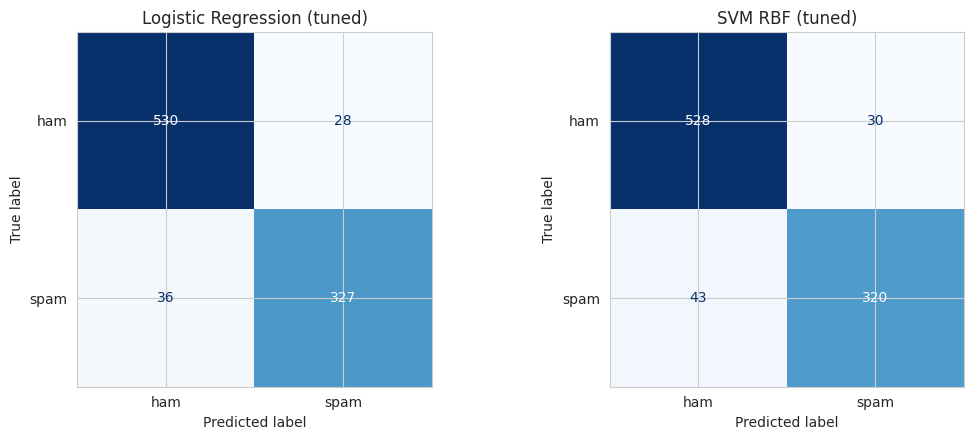

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [("Logistic Regression (tuned)", final_lr), (f"SVM {best_kernel.upper()} (tuned)", final_svm)]):
    cm = confusion_matrix(y_test, model.predict(X_test_scaled))
    ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/fig_09_final_confusion.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Logistic regression produces 530 true negatives, 28 false positives, 36 false negatives and
327 true positives. The RBF SVM produces 528, 30, 43 and 320. Both models miss more spam
than they wrongly flag, but 28 to 30 legitimate emails sent to the spam folder (about 5% of
all ham) would be too costly for a real filter. In deployment the decision threshold should
be moved to protect ham, trading some recall for fewer false positives.

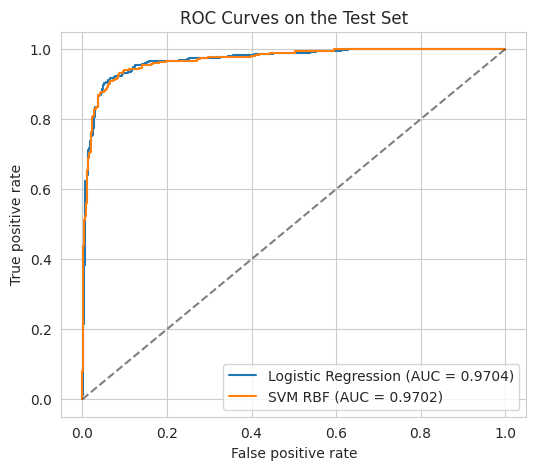

In [42]:
plt.figure(figsize=(6, 5))
for name, model in [("Logistic Regression", final_lr), (f"SVM {best_kernel.upper()}", final_svm)]:
    fpr, tpr, _ = roc_curve(y_test, model.decision_function(X_test_scaled))
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, model.decision_function(X_test_scaled)):.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curves on the Test Set")
plt.legend(loc="lower right")
plt.savefig("figures/fig_10_roc.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The two ROC curves overlap almost completely and their areas are 0.9704 for logistic
regression and 0.9702 for the RBF SVM, so neither model is better at separating the classes
across all thresholds.

## 5-Fold Cross-Validation

In [43]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_lr = cross_val_score(final_lr, X_train_scaled, y_train, cv=skf, scoring="accuracy")
cv_svm = cross_val_score(final_svm, X_train_scaled, y_train, cv=skf, scoring="accuracy")
cv_table = pd.DataFrame({"Logistic Regression": cv_lr, f"SVM ({best_kernel.upper()})": cv_svm},
                        index=[f"Fold {i+1}" for i in range(5)])
cv_table.loc["Average"] = cv_table.mean()
cv_table.loc["Std Dev"] = cv_table.iloc[:5].std()

In [44]:
cv_table
cv_table

,Logistic Regression,SVM (RBF)
Fold 1,0.937500,0.944293
Fold 2,0.925272,0.941576
Fold 3,0.930707,0.934783
Fold 4,0.907609,0.930707
Fold 5,0.917120,0.926630
Average,0.923641,0.935598
Std Dev,0.011664,0.007355


In [45]:
cv_table
cv_table

,Logistic Regression,SVM (RBF)
Fold 1,0.937500,0.944293
Fold 2,0.925272,0.941576
Fold 3,0.930707,0.934783
Fold 4,0.907609,0.930707
Fold 5,0.917120,0.926630
Average,0.923641,0.935598
Std Dev,0.011664,0.007355


|  | Logistic Regression | SVM (RBF) |
|---|---|---|
| Fold 1 | 0.9375 | 0.9443 |
| Fold 2 | 0.9253 | 0.9416 |
| Fold 3 | 0.9307 | 0.9348 |
| Fold 4 | 0.9076 | 0.9307 |
| Fold 5 | 0.9171 | 0.9266 |
| Average | 0.9236 | 0.9356 |
| Std Dev | 0.0117 | 0.0074 |

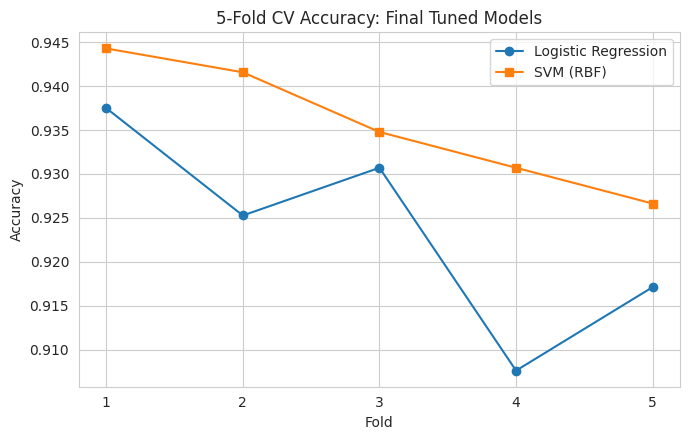

In [46]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(1, 6)
ax.plot(x, cv_lr, marker="o", label="Logistic Regression")
ax.plot(x, cv_svm, marker="s", label=f"SVM ({best_kernel.upper()})")
ax.set_xticks(x)
ax.set_xlabel("Fold")
ax.set_ylabel("Accuracy")
ax.set_title("5-Fold CV Accuracy: Final Tuned Models")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_11_cv_folds.png", dpi=110, bbox_inches="tight")
plt.show()

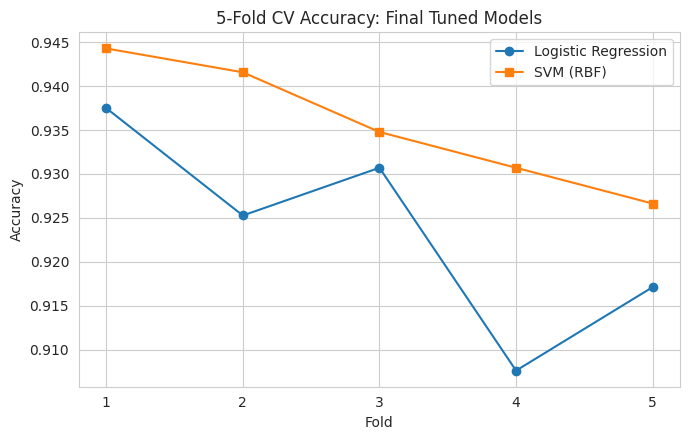

In [47]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(1, 6)
ax.plot(x, cv_lr, marker="o", label="Logistic Regression")
ax.plot(x, cv_svm, marker="s", label=f"SVM ({best_kernel.upper()})")
ax.set_xticks(x)
ax.set_xlabel("Fold")
ax.set_ylabel("Accuracy")
ax.set_title("5-Fold CV Accuracy: Final Tuned Models")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_11_cv_folds.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Across the five stratified folds the RBF SVM averages 0.9356 (standard deviation 0.0074) and
logistic regression 0.9236 (0.0117). The SVM wins in every fold, and its scores vary less
between folds. This ranking is the opposite of the test-set ranking, and these cross-
validation scores are measured on the training set that was already used for tuning, so they
are slightly optimistic. Taken together, the two evaluations show a difference of about one
percentage point that changes sign, which is what noise looks like.

## Bias-Variance Analysis

In [48]:
bv_rows = [("Logistic Regression", final_lr, grid_lr.best_score_)]
bv_rows += [(f"SVM {k}", fitted_tuned_svms[k], svm_tuned_df.loc[k, "Best CV Accuracy"]) for k in kernels]
bv = pd.DataFrame([{"Model": n, "Train accuracy": m.score(X_train_scaled, y_train), "CV accuracy": cv_acc,
                    "Test accuracy": m.score(X_test_scaled, y_test)} for n, m, cv_acc in bv_rows])
bv["Train-CV gap"] = bv["Train accuracy"] - bv["CV accuracy"]

In [49]:
bv
bv

,Model,Train accuracy,CV accuracy,Test accuracy,Train-CV gap
0,Logistic Regression,0.929891,0.924185,0.930510,0.005707
1,SVM linear,0.935054,0.930435,0.927253,0.004620
2,SVM poly,0.952989,0.917935,0.916395,0.035054
3,SVM rbf,0.970109,0.933152,0.920738,0.036957
4,SVM sigmoid,0.895652,0.891033,0.889251,0.004620


In [50]:
bv
bv

,Model,Train accuracy,CV accuracy,Test accuracy,Train-CV gap
0,Logistic Regression,0.929891,0.924185,0.930510,0.005707
1,SVM linear,0.935054,0.930435,0.927253,0.004620
2,SVM poly,0.952989,0.917935,0.916395,0.035054
3,SVM rbf,0.970109,0.933152,0.920738,0.036957
4,SVM sigmoid,0.895652,0.891033,0.889251,0.004620


| Model | Train accuracy | CV accuracy | Test accuracy | Train-CV gap |
|---|---|---|---|---|
| Logistic Regression | 0.9299 | 0.9242 | 0.9305 | 0.0057 |
| SVM linear | 0.9351 | 0.9304 | 0.9273 | 0.0046 |
| SVM poly | 0.9530 | 0.9179 | 0.9164 | 0.0351 |
| SVM rbf | 0.9701 | 0.9332 | 0.9207 | 0.0370 |
| SVM sigmoid | 0.8957 | 0.8910 | 0.8893 | 0.0046 |


**Inference:** The models with a small train-CV gap (logistic regression 0.006, linear SVM 0.005, sigmoid
SVM 0.005) have low variance. Among them the sigmoid SVM also has the lowest training
accuracy (0.896), so it is a high-bias model that underfits. The RBF (gap 0.037) and
polynomial (gap 0.035) SVMs fit the training data much more closely (0.970 and 0.953) but
lose about three and a half points in cross-validation and on the test set, which is the
signature of higher variance. Their extra flexibility did not translate into better
generalisation than the linear models.

## Summary Tables

In [51]:
tuning_summary = pd.DataFrame({
    "Model": ["Logistic Regression", f"SVM ({best_kernel.upper()})"],
    "Search Method": ["Grid Search (5-fold CV)", "Grid Search (5-fold CV)"],
    "Best Parameters": [", ".join(f"{k}={v}" for k, v in grid_lr.best_params_.items()), svm_tuned_df.loc[best_kernel, "Best Parameters"]],
    "Best CV Accuracy": [grid_lr.best_score_, svm_tuned_df.loc[best_kernel, "Best CV Accuracy"]],
})
comparative = pd.DataFrame({
    "Logistic Regression": [f"{cv_lr.mean():.4f}", "Low", f"{grid_lr_time:.1f} s (20 combinations)", "High (coefficients are interpretable)"],
    f"SVM ({best_kernel.upper()})": [f"{cv_svm.mean():.4f}", "High", f"{svm_tuned_df.loc[best_kernel, 'Search Time (s)']:.1f} s (one kernel grid)", "Low (implicit kernel space)"],
}, index=["Accuracy (5-fold CV)", "Model Complexity", "Search Time", "Interpretability"])

In [52]:
tuning_summary
tuning_summary

,Model,Search Method,Best Parameters,Best CV Accuracy
0,Logistic Regression,Grid Search (5-fold CV),"C=1, penalty=l2, solver=saga",0.924185
1,SVM (RBF),Grid Search (5-fold CV),"C=10, gamma=scale",0.933152


In [53]:
tuning_summary
tuning_summary

,Model,Search Method,Best Parameters,Best CV Accuracy
0,Logistic Regression,Grid Search (5-fold CV),"C=1, penalty=l2, solver=saga",0.924185
1,SVM (RBF),Grid Search (5-fold CV),"C=10, gamma=scale",0.933152


| Model | Search Method | Best Parameters | Best CV Accuracy |
|---|---|---|---|
| Logistic Regression | Grid Search (5-fold CV) | C=1, penalty=l2, solver=saga | 0.9242 |
| SVM (RBF) | Grid Search (5-fold CV) | C=10, gamma=scale | 0.9332 |

In [54]:
comparative
comparative

,Logistic Regression,SVM (RBF)
Accuracy (5-fold CV),0.9236,0.9356
Model Complexity,Low,High
Search Time,268.6 s (20 combinations),10.1 s (one kernel grid)
Interpretability,High (coefficients are interpretable),Low (implicit kernel space)


In [55]:
comparative
comparative

,Logistic Regression,SVM (RBF)
Accuracy (5-fold CV),0.9236,0.9356
Model Complexity,Low,High
Search Time,268.6 s (20 combinations),10.1 s (one kernel grid)
Interpretability,High (coefficients are interpretable),Low (implicit kernel space)


|  | Logistic Regression | SVM (RBF) |
|---|---|---|
| Accuracy (5-fold CV) | 0.9236 | 0.9356 |
| Model Complexity | Low | High |
| Search Time | 268.6 s (20 combinations) | 9.6 s (one kernel grid) |
| Interpretability | High (coefficients are interpretable) | Low (implicit kernel space) |

# Discussion



Both classifiers were tuned with the same stratified cross-validation protocol on a
standardised 3680-email training set and judged on the same 921 test emails, so the
comparison is fair, although the differences found are small.

**Which classifier performed best?** No model is clearly best. Logistic regression has the best test accuracy and F1 (0.9305 and 0.911), the RBF SVM has the best cross-validation accuracy (0.9356 against 0.9236 on the final folds), and the ROC-AUC is the same (0.970). With 921 test emails the sampling error of an accuracy near 93% is about 0.85 percentage points, so differences of one point cannot be called significant. Logistic regression is the more sensible default here because it matches the SVM within noise, is simpler and its coefficients can be inspected (and with the liblinear solver it also fits in a fraction of a second).

**What is the impact of regularisation?** Regularisation strength mattered more than regularisation type. At C = 0.01 both penalties underfit (CV accuracy 0.875 for L1 and 0.913 for L2 with liblinear), and from C = 1 upwards accuracy is flat near 0.923. L1 behaves differently from L2 only at strong regularisation: it removes 31 of 57 features at C = 0.01 and 16 at C = 0.05, with no loss of accuracy at C = 0.05, while L2 keeps all 57. The choice of solver changed run time (liblinear is much faster here) but not accuracy.

**How do the SVM kernels behave?** The linear and RBF kernels both reach about 93% accuracy, which suggests that the classes are already close to linearly separable in the 57-dimensional space and that a non-linear boundary adds little. The polynomial kernel is very sensitive to its settings (0.780 at degree 3 and C = 1 against 0.916 at degree 2 and C = 10). The sigmoid kernel is consistently the weakest (about 0.89), since it is not a valid positive semi-definite kernel for all parameter values. A larger C lets the SVM fit the training data more tightly, as the next table shows.

**What does the bias-variance trade-off show?** The train-CV gap in the table shows the variance of each model. Logistic regression has train accuracy 0.930 and CV accuracy 0.924, a gap of about 0.006, so it has higher bias (it cannot go beyond a linear boundary) but very low variance. The tuned RBF SVM reaches 0.970 on the training data against 0.933 in CV, a gap of about 0.037, so it fits the training set much more closely and generalises with a larger loss, which is typical of a flexible model with C = 10. The polynomial SVM shows the same pattern (gap about 0.035), while the linear SVM has a gap of only about 0.005. The extra flexibility of RBF bought roughly one point of CV accuracy and nothing on the test set.

# Conclusion



Logistic regression and SVMs with different kernels were trained and tuned on the Spambase
data with 5-fold cross-validation. Tuned logistic regression (C = 1, L2) reached 93.05% test
accuracy with F1 0.911, and the best SVM by cross-validation (RBF, C = 10) reached 92.07%
with F1 0.898; both have ROC-AUC 0.970. Regularisation strength mattered more than the
penalty type, L1 gave sparse models only at strong regularisation, liblinear was as accurate
as saga and much faster, and kernel choice mattered mostly for the polynomial and sigmoid
kernels. The differences between the two best models are within the sampling error of the
test set, so the simpler and more interpretable logistic regression is recommended. A
practical spam filter would also need a higher decision threshold to cut the roughly 5% of
legitimate emails wrongly flagged, and the dataset's single-mailbox origin limits how well
any of these models would transfer.

# References



[1] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," Journal of Machine Learning Research, vol. 12, pp. 2825-2830, 2011.

[2] C. Cortes and V. Vapnik, "Support-vector networks," Machine Learning, vol. 20, no. 3, pp. 273-297, 1995.

[3] D. W. Hosmer, S. Lemeshow and R. X. Sturdivant, Applied Logistic Regression, 3rd ed. Wiley, 2013.

[4] M. Hopkins, E. Reeber, G. Forman and J. Suermondt, "Spambase Data Set," UCI Machine Learning Repository, 1999. [Online]. Available: https://archive.ics.uci.edu/dataset/94/spambase

[5] Spambase Dataset, Kaggle. [Online]. Available: https://www.kaggle.com/datasets/somesh24/spambase